In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
 )
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df_model = pd.read_csv("../data/diabetes.csv").dropna(subset=["Outcome"]).copy()
X = df_model.drop(columns=["Outcome"])
y = df_model["Outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

results = {}
trained_models = {}

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    }

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Không mắc (0)", "Mắc (1)"]
    )
    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

    return y_pred


===== SVM =====
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



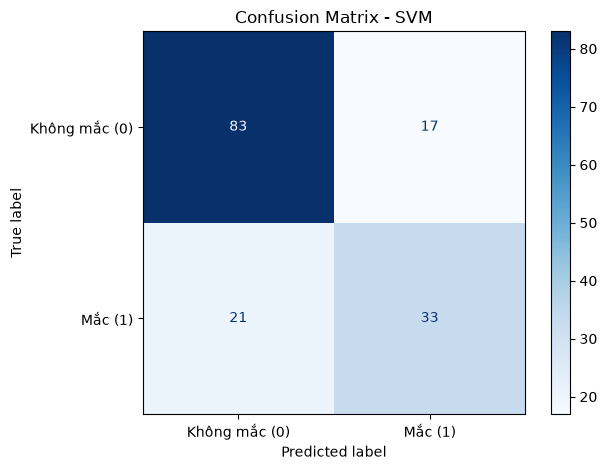

In [6]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_model.fit(X_train, y_train)

trained_models["SVM"] = svm_model

svm_pred = evaluate_model(
    "SVM",
    svm_model,
    X_test,
    y_test
)

SO SÁNH 3 MÔ HÌNH

In [7]:
comparison = pd.DataFrame(results).T

print("Bảng so sánh mô hình:")
display(comparison.round(4))

Bảng so sánh mô hình:


,Accuracy,Precision,Recall,F1-score
SVM,0.7532,0.66,0.6111,0.6346


VẼ BIỂU ĐỒ

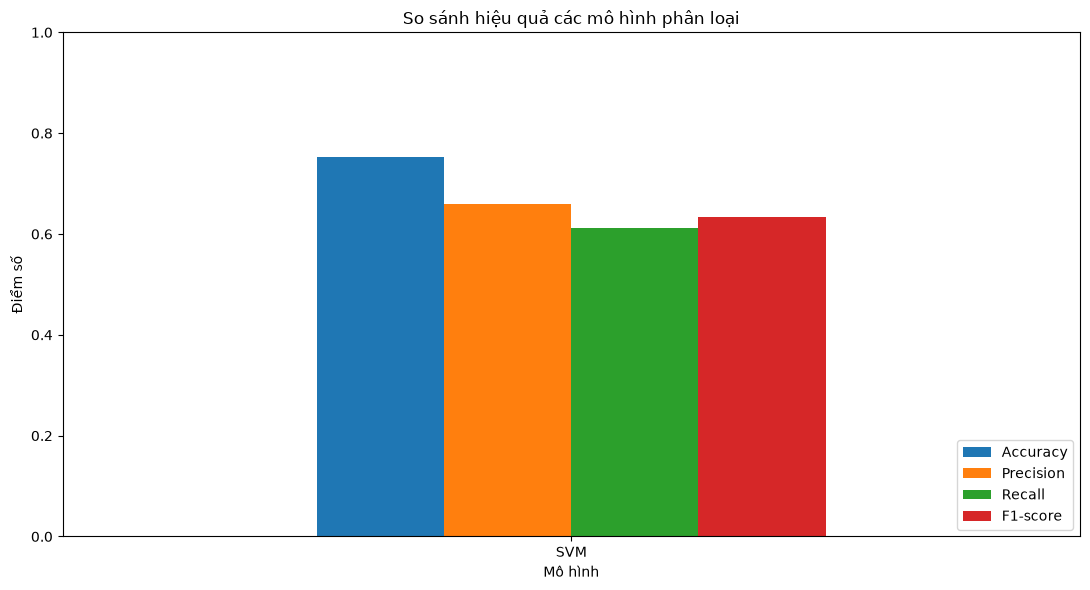

In [8]:
comparison.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("So sánh hiệu quả các mô hình phân loại")
plt.ylabel("Điểm số")
plt.xlabel("Mô hình")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=200,
            bbox_inches="tight")
plt.show()

TỐI ƯU THAM SỐ BẰNG GRIDSEARCHCV 

1. TỐI ƯU DECISION TREE

Tham số tốt nhất: {'classifier__max_depth': 7, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}
Recall CV tốt nhất: 0.551827242524917

===== Decision Tree tuned =====
              precision    recall  f1-score   support

           0       0.77      0.91      0.83       100
           1       0.75      0.50      0.60        54

    accuracy                           0.77       154
   macro avg       0.76      0.71      0.72       154
weighted avg       0.76      0.77      0.75       154



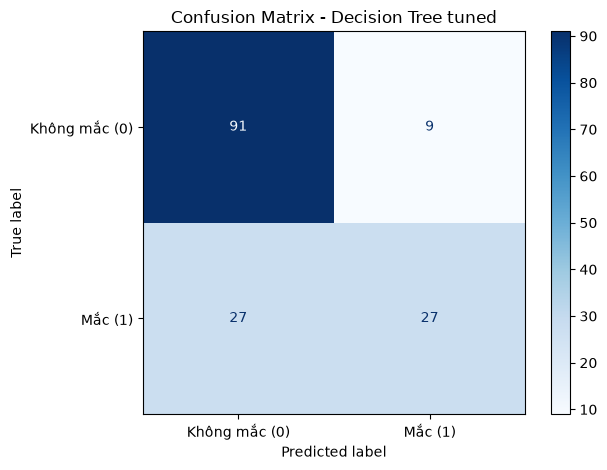

array([1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0])

In [9]:
from sklearn.model_selection import GridSearchCV

dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

dt_params = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5]
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_params,
    scoring="recall",
    cv=5,
    n_jobs=-1,
    refit=True
)

dt_grid.fit(X_train, y_train)

print("Tham số tốt nhất:", dt_grid.best_params_)
print("Recall CV tốt nhất:", dt_grid.best_score_)

best_dt = dt_grid.best_estimator_

trained_models["Decision Tree tuned"] = best_dt

evaluate_model(
    "Decision Tree tuned",
    best_dt,
    X_test,
    y_test
)

2. TỐI ƯU RANDOM FOREST

Tham số tốt nhất: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
Recall CV tốt nhất: 0.6077519379844961

===== Random Forest tuned =====
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       100
           1       0.65      0.59      0.62        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.72       154
weighted avg       0.74      0.75      0.74       154



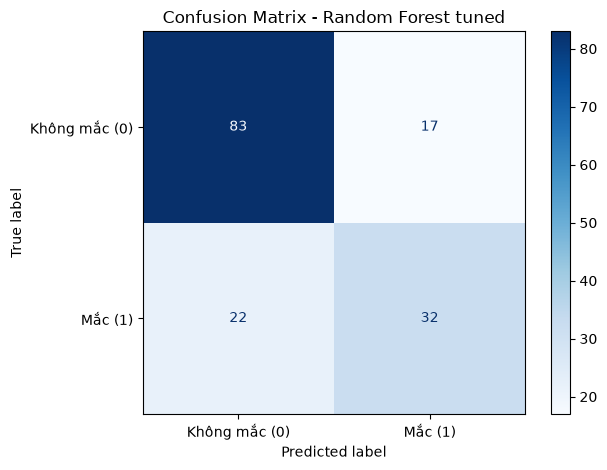

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0])

In [10]:
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring="recall",
    cv=5,
    n_jobs=-1,
    refit=True
)

rf_grid.fit(X_train, y_train)

print("Tham số tốt nhất:", rf_grid.best_params_)
print("Recall CV tốt nhất:", rf_grid.best_score_)

best_rf = rf_grid.best_estimator_

trained_models["Random Forest tuned"] = best_rf

evaluate_model(
    "Random Forest tuned",
    best_rf,
    X_test,
    y_test
)